# Evaluación del contexto de seguridad de una propiedad en Washington
## V2 | Datos desde GitHub | Tarea grupal 2. Opción 2 | Datos de 2023

**Curso:** Introducción a Datos Espaciales  
**Grupo:** Colombia 
**Fecha de presentación:** 03/11/2026

| Integrante | Nombres y apellidos | Código |
|---|---|---|
| 1 | Bautista Janampa José | 20220430 |
| 2 | Saldaña Ruiz Maria Milagros | 20241445 |
| 3 | Diaz Sulca Andrea Ariana | 20245499 |

Este informe compara los condados de Washington mediante el indicador solicitado en la actividad y ubica una propiedad real dentro de ese contexto. Integra preparación de datos, revisión cartográfica, unión de tablas, clasificación, mapas, consulta espacial y una recomendación que se calcula al ejecutar el cuaderno.

**Pregunta de análisis:** ¿qué posición ocupa el condado de la propiedad respecto a los demás condados de Washington, según los casos judiciales por agresiones y drogas relativos a su población en 2023?


## 1. Objetivo y alcance

Se emplea exclusivamente la siguiente razón para cada condado:

\[
I_{2023}=\frac{\mathrm{SCF\_ASSAULT}_{2023}+\mathrm{SCF\_DRUG\_CR}_{2023}}{\mathrm{POP\_TOTAL}_{2023}}
\]

Para que las cifras sean más fáciles de leer, los mapas y tablas muestran también $I\times10\,000$. Es el mismo indicador expresado por cada 10 000 habitantes, no una segunda medida de seguridad.

Según el diccionario proporcionado, SCF significa "Superior Court Filing": el ingreso de un caso al Tribunal Superior. Se registra un caso por acusado y se clasifica por el cargo original más grave. El año corresponde al ingreso judicial, no necesariamente al momento en que ocurrió el hecho. Estas cifras no equivalen al total de delitos, de víctimas ni de condenas.

| Campo | Significado | Ubicación en el PDF |
|---|---|---|
| `year` | Año de reporte. Se conserva 2023. | Página 2, impresa 1 |
| `county` | Condado o jurisdicción que reporta. | Página 2, impresa 1 |
| `POP_TOTAL` | Población total, ambos sexos y todas las edades, estimada por el Office of Financial Management. | Página 2, impresa 1 |
| `SCF_ASSAULT` | Casos cuyo cargo principal involucra agresión o intención de causar daño físico, incluido acoso malicioso y coacción. | Página 13, impresa 12 |
| `SCF_DRUG_CR` | Casos cuyo cargo principal involucra infracciones sobre sustancias controladas o medicamentos con receta. | Página 14, impresa 13 |

La comparación estadística se realiza por condado. Las zonas censales permiten ubicar la propiedad con mayor detalle. Una sección complementaria muestra la interpolación areal vista en clase y explica por qué, con estos insumos, no permite distinguir la seguridad entre zonas de un mismo condado.


## 2. Preparación y lectura desde GitHub

Este cuaderno obtiene sus insumos del repositorio público [Evaluacion_Grupal_2](https://github.com/Jose-Bautista-gnss/Evaluacion_Grupal_2), carpeta `Data`. No requiere una carpeta Data previa ni una ruta del disco D:. Puede abrirse en VS Code con el kernel de tu `.venv` o cargarse directamente en Google Colab.

La primera celda instala únicamente las bibliotecas ausentes, utilizando el mismo Python del kernel. No actualiza automáticamente las que ya estén instaladas. La primera ejecución necesita conexión. Ejecuta las celdas en orden; no pegues este código en PowerShell.

Los insumos se descargan a `.cache_t2/<commit>/Data` dentro de la carpeta de ejecución. La caché se verifica antes de reutilizarse. Los resultados se guardan en `Resultados_V2`; los archivos originales del repositorio no se modifican ni se publican resultados automáticamente.

Las herramientas principales son las de clase: pandas, GeoPandas, Matplotlib, mapclassify, geopy, `merge`, `dissolve`, `sjoin`, `explore` y Tobler. El Census Geocoder se utiliza para localizar la dirección; Nominatim es una alternativa si ese servicio no devuelve una coincidencia válida.


In [1]:
import sys
import importlib.util
import subprocess

requeridos = {
    'numpy': 'numpy', 'pandas': 'pandas', 'openpyxl': 'openpyxl',
    'geopandas': 'geopandas>=1.0', 'matplotlib': 'matplotlib',
    'mapclassify': 'mapclassify', 'geopy': 'geopy', 'folium': 'folium',
    'branca': 'branca', 'tobler': 'tobler', 'pypdf': 'pypdf'
}
ausentes = [paquete for modulo, paquete in requeridos.items()
            if importlib.util.find_spec(modulo) is None]
if ausentes:
    print('Instalando en el kernel activo:', ', '.join(ausentes))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *ausentes])
else:
    print('Las bibliotecas necesarias ya están disponibles.')
print('Python del kernel:', sys.executable)


Instalando en el kernel activo: geopy, tobler


Python del kernel: d:\Python\.venv\Scripts\python.exe


In [2]:
from pathlib import Path
import sys
import re
import json
import hashlib
import zipfile
import html
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import mapclassify
from geopy.geocoders import Nominatim
from shapely.geometry import Point
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 25)
plt.rcParams.update({'font.size': 10, 'figure.dpi': 120})
print('Intérprete:', sys.executable)
print('Directorio actual:', Path.cwd())

from io import BytesIO
from urllib.request import Request, urlopen
from urllib.parse import quote, urlencode
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from pypdf import PdfReader
import time


Intérprete: d:\Python\.venv\Scripts\python.exe
Directorio actual: d:\pucp\9no ciclo\Datos espaciales\Códigos Python\Tareas grupales\T2


## 3. Configuración del análisis

El repositorio se consulta en la rama `main`. Al ejecutar la descarga se resuelve su commit y se leen todos los archivos desde esa versión, para evitar mezclar cambios hechos durante la ejecución. El commit y los enlaces de los insumos se guardan en la trazabilidad.

La dirección inicial es **1321 Seneca St, Seattle, WA 98101**, un edificio residencial documentado por la ciudad de Seattle. Es un caso académico editable; no se afirma que una unidad concreta esté en venta. Si el grupo elige otra propiedad, cambia la dirección, su fuente y el condado esperado. Las coordenadas manuales solo deben utilizarse con una fuente verificable.


In [3]:
ANIO = 2023
ESCALA = 10_000
CRS_ANALISIS = 'EPSG:5070'
REPOSITORIO = 'Jose-Bautista-gnss/Evaluacion_Grupal_2'
REFERENCIA_GITHUB = 'main'  # También admite el SHA de un commit para fijar la versión.
BASE = Path.cwd()
SALIDA = BASE / 'Resultados_V2'
SALIDA.mkdir(exist_ok=True)
PRESENTACION = BASE / 'Presentacion_V2'

DIRECCION = '1321 Seneca St, Seattle, WA 98101, USA'
FUENTE_DIRECCION = 'https://www.seattle.gov/dpd/AppDocs/GroupMeetings/DRProposal3012930AgendaID4238.pdf'
CONDADO_ESPERADO = 'KING'
COORDENADAS_MANUALES = None  # (longitud, latitud), en WGS84, si se necesitan.
FUENTE_COORDENADAS = ''
EJECUTAR_INTERPOLACION = True
CREAR_MAPA_INTERACTIVO = True
GENERAR_PLANTILLA_R = True
CAMPO_NOMBRE_CONDADO = None
CAMPO_FIPS_CONDADO = None

EN_COLAB = 'google.colab' in sys.modules
print('Entorno:', 'Google Colab' if EN_COLAB else 'Jupyter local / VS Code')
print('Repositorio:', 'https://github.com/' + REPOSITORIO)
print('Carpeta de resultados:', SALIDA)


Entorno: Jupyter local / VS Code
Repositorio: https://github.com/Jose-Bautista-gnss/Evaluacion_Grupal_2
Carpeta de resultados: d:\pucp\9no ciclo\Datos espaciales\Códigos Python\Tareas grupales\T2\Resultados_V2


## 4. Descarga, inventario y lectura de los insumos

Se consulta el inventario real de `Data` y se descarga cada archivo. El Excel, los dos shapefiles completos, los ZIP y el diccionario proceden de GitHub. Los ZIP permiten leer una capa con todos sus auxiliares sin depender del acceso remoto de GDAL, que puede variar entre sistemas operativos. La lectura se realiza sobre los bytes descargados desde GitHub, utilizando `BytesIO`.

Antes de usar un archivo, se comprueban su tamaño y su identificador Git. Una copia incompleta o de otra versión se descarga otra vez. Si GitHub no está disponible, el proceso muestra un error; no sustituye los insumos por datos simulados.


In [4]:
def obtener_bytes(url, intentos=3):
    ultimo_error = None
    for intento in range(intentos):
        try:
            peticion = Request(url, headers={'User-Agent': 'pucp-t2-washington-v2'})
            with urlopen(peticion, timeout=60) as respuesta:
                return respuesta.read()
        except Exception as exc:
            ultimo_error = exc
            if intento + 1 < intentos:
                time.sleep(1 + intento)
    raise RuntimeError(f'No se pudo descargar {url}. Revisa la conexión y el acceso al repositorio.') from ultimo_error

api = 'https://api.github.com/repos/' + REPOSITORIO
commit_info = json.loads(obtener_bytes(api + '/commits/' + quote(REFERENCIA_GITHUB, safe='')))
COMMIT_GITHUB = commit_info['sha']
URL_BASE_DATOS = f'https://raw.githubusercontent.com/{REPOSITORIO}/{COMMIT_GITHUB}/Data/'
contenido = json.loads(obtener_bytes(api + '/contents/Data?ref=' + COMMIT_GITHUB))
if not isinstance(contenido, list):
    raise ValueError('La respuesta de GitHub no contiene un inventario de Data.')
archivos_remotos = [a for a in contenido if a['type'] == 'file']
if not archivos_remotos:
    raise ValueError('La carpeta Data del repositorio está vacía.')
if any(a['type'] == 'dir' for a in contenido):
    raise ValueError('Hay subcarpetas en Data. Revisar el inventario antes de continuar.')
DATA = BASE / '.cache_t2' / COMMIT_GITHUB / 'Data'
DATA.mkdir(parents=True, exist_ok=True)

def sha_git(blob):
    return hashlib.sha1(b'blob ' + str(len(blob)).encode('ascii') + b'\0' + blob).hexdigest()

def descargar_archivo(archivo):
    nombre = archivo['name']
    if Path(nombre).name != nombre:
        raise ValueError('Nombre de archivo no permitido en el inventario.')
    destino = DATA / nombre
    url = URL_BASE_DATOS + quote(nombre, safe='')
    blob = destino.read_bytes() if destino.exists() else None
    desde_cache = blob is not None and len(blob) == archivo['size'] and sha_git(blob) == archivo['sha']
    if not desde_cache:
        blob = obtener_bytes(url)
        if len(blob) != archivo['size'] or sha_git(blob) != archivo['sha']:
            raise ValueError(f'El contenido de {nombre} no coincide con el registrado por GitHub.')
        temporal = destino.with_name(destino.name + '.part')
        temporal.write_bytes(blob)
        temporal.replace(destino)
    return {'archivo': nombre, 'tamano_KB': round(len(blob) / 1024, 1),
            'sha_git': archivo['sha'], 'url': url, 'cache_verificada': desde_cache}

with ThreadPoolExecutor(max_workers=4) as grupo_descargas:
    registros_descarga = list(grupo_descargas.map(descargar_archivo, archivos_remotos))
inventario = pd.DataFrame(registros_descarga).sort_values('archivo')
print('Commit:', COMMIT_GITHUB)
display(inventario[['archivo', 'tamano_KB', 'cache_verificada']])
necesarios = {'cjdb90_23.xlsx', 'cjdb_dictionary.pdf', 'condados_WA.zip', 'zonas_censales_WA.zip'}
faltantes = necesarios - set(inventario.archivo)
if faltantes:
    raise FileNotFoundError(f'Faltan estos insumos en GitHub: {faltantes}')

libro = pd.ExcelFile(BytesIO((DATA / 'cjdb90_23.xlsx').read_bytes()))
datos = pd.read_excel(libro, sheet_name='CJDB90_23' if 'CJDB90_23' in libro.sheet_names else 0)
condados_original = gpd.read_file(BytesIO((DATA / 'condados_WA.zip').read_bytes()))
censales_original = gpd.read_file(BytesIO((DATA / 'zonas_censales_WA.zip').read_bytes()))
diccionario = PdfReader(BytesIO((DATA / 'cjdb_dictionary.pdf').read_bytes()))
print('Diccionario PDF:', len(diccionario.pages), 'páginas')
for pagina, termino in [(1, 'POP_TOTAL'), (12, 'SCF_ASSAULT'), (13, 'SCF_DRUG_CR')]:
    texto = diccionario.pages[pagina].extract_text() or ''
    posicion = texto.find(termino)
    if posicion < 0:
        raise ValueError(f'Revisar la definición de {termino}; cambió el diccionario.')
    print(f'Página {pagina + 1}:', texto[posicion:posicion + 320].split('\n\n')[0])
display(datos[['year', 'county', 'POP_TOTAL', 'SCF_ASSAULT', 'SCF_DRUG_CR']].head(3))
for nombre, capa in [('Condados', condados_original), ('Zonas censales', censales_original)]:
    print(f'\n{nombre}: {len(capa)} entidades | CRS: {capa.crs}')
    print('Campos:', capa.columns.tolist())
    display(capa.drop(columns='geometry').head(3))


Commit: 9ca12e91cd4b3da874505ba7ad9895b498cf9e99


,archivo,tamano_KB,cache_verificada
0,WA_County_Boundaries.cpg,0.0,False
1,WA_County_Boundaries.dbf,4.6,False
2,WA_County_Boundaries.prj,0.4,False
3,WA_County_Boundaries.shp,1703.8,False
4,WA_County_Boundaries.shx,0.4,False
5,WA_County_Boundaries.xml,2.8,False
6,cb_2018_53_tract_500k.cpg,0.0,False
7,cb_2018_53_tract_500k.dbf,246.0,False
8,cb_2018_53_tract_500k.prj,0.2,False
9,cb_2018_53_tract_500k.shp,1793.1,False


Diccionario PDF: 17 páginas
Página 2: POP_TOTAL: Total population, males and females, all ages. 
 
Uniform Crime Reporting 
The Summary Reporting System (SRS) has been a national method of collecting Uniform Crime Reporting statistics 
for the FBI since the 1930s. The National Incident -Based Reporting System (NIBRS) was developed in the 1980s to 
illustra
Página 13: SCF_ASSAULT: Cases where the primary charge involves assault or intent to cause another person 
physical harm, including malicious harassment and coercion. 
Página 14: SCF_DRUG_CR: Cases where the primary charge involves violation of the Uniform Controlled Substances 
Act or violation of regulations regarding prescription drugs. 
o SCF_HOMICIDE: Cases where the primary charge involves murder, manslaughter, excusable homicide, 
or justifiable homicide. 
o SCF_MVT: Cases where the prim


,year,county,POP_TOTAL,SCF_ASSAULT,SCF_DRUG_CR
0,1990,ADAMS,13603,13,32
1,1991,ADAMS,13798,15,49
2,1992,ADAMS,14143,10,47



Condados: 39 entidades | CRS: EPSG:3857
Campos: ['OBJECTID', 'JURISDICT_', 'JURISDIC_1', 'JURISDIC_2', 'JURISDIC_3', 'JURISDIC_4', 'JURISDIC_5', 'JURISDIC_6', 'EDIT_DATE', 'EDIT_STATU', 'EDIT_WHO', 'GLOBALID', 'geometry']


,OBJECTID,JURISDICT_,JURISDIC_1,JURISDIC_2,JURISDIC_3,JURISDIC_4,JURISDIC_5,JURISDIC_6,EDIT_DATE,EDIT_STATU,EDIT_WHO,GLOBALID
0,1693004,25,4,Grant,Grant County,13,53025,None,2018-03-15,1,TSTE490,{08C55344-4269-4294-B0DB-6D794D45C52F}
1,1697154,33,4,Garfield,Garfield County,12,53023,None,2022-06-23,1,TSTE490,{8070C422-340E-47D0-90BD-CA7970679756}
2,1697516,8,4,Island,Island County,15,53029,None,2018-03-15,1,TSTE490,{DCDFC2FA-FBBF-4F98-8088-99162C9A07E2}



Zonas censales: 1454 entidades | CRS: EPSG:4269
Campos: ['STATEFP', 'COUNTYFP', 'TRACTCE', 'AFFGEOID', 'GEOID', 'NAME', 'LSAD', 'ALAND', 'AWATER', 'geometry']


,STATEFP,COUNTYFP,TRACTCE,AFFGEOID,GEOID,NAME,LSAD,ALAND,AWATER
0,53,067,010520,1400000US53067010520,53067010520,105.20,CT,3715505,586278
1,53,067,011622,1400000US53067011622,53067011622,116.22,CT,2166821,460169
2,53,071,920701,1400000US53071920701,53071920701,9207.01,CT,1853528,0


## 5. Preparación espacial y claves de unión

`to_crs` transforma las coordenadas desde el sistema original. No se usa `set_crs` para forzar una ubicación. EPSG:5070 permite trabajar en metros y comparar superficies en Estados Unidos continental. El mapa interactivo y la geocodificación utilizan EPSG:4326, que expresa longitud y latitud.

La unión con el Excel parte del nombre normalizado del condado. Después se conserva el código FIPS como texto, incluidos sus ceros iniciales. Para las zonas censales, los dos dígitos de `STATEFP` y los tres de `COUNTYFP` forman ese mismo código de condado. El valor de `NAME` de una zona censal no es el nombre del condado.


In [5]:
def preparar_geometria(capa, nombre):
    if capa.crs is None:
        raise ValueError(f'{nombre}: falta el CRS. Revisar el archivo .prj antes de continuar.')
    if capa.geometry.isna().any() or capa.geometry.is_empty.any():
        raise ValueError(f'{nombre}: hay geometrías vacías o ausentes.')
    resultado = capa.to_crs(CRS_ANALISIS).copy()
    invalidas = ~resultado.geometry.is_valid
    print(f'{nombre}: {invalidas.sum()} geometrías inválidas antes de la revisión.')
    if invalidas.any():
        resultado.loc[invalidas, 'geometry'] = resultado.loc[invalidas, 'geometry'].make_valid()
    if (~resultado.geometry.is_valid).any() or not resultado.geom_type.isin(['Polygon', 'MultiPolygon']).all():
        raise ValueError(f'{nombre}: revisar las geometrías; se requieren polígonos válidos.')
    return resultado

condados = preparar_geometria(condados_original, 'Condados')
censales = preparar_geometria(censales_original, 'Zonas censales')

def elegir_campo(capa, manual, opciones):
    if manual is not None:
        if manual not in capa.columns:
            raise KeyError(f'No existe el campo configurado: {manual}')
        return manual
    for nombre in opciones:
        if nombre in capa.columns:
            return nombre
    raise KeyError(f'No se identificó el campo. Revisa las columnas y configura uno de: {opciones}')

campo_nombre = elegir_campo(condados, CAMPO_NOMBRE_CONDADO,
                            ['JURISDIC_2', 'NAME', 'COUNTY_NM', 'COUNTYNAME'])
campo_fips = elegir_campo(condados, CAMPO_FIPS_CONDADO,
                          ['JURISDIC_5', 'GEOID', 'FIPS', 'fips_id'])

def normalizar_nombres(serie):
    return serie.astype('string').str.strip().str.upper().str.replace(r'\s+COUNTY$', '', regex=True)

def texto_codigo(serie, ancho):
    texto = serie.astype('string').str.strip().str.replace(r'\.0$', '', regex=True)
    if not texto.str.fullmatch(r'\d+').fillna(False).all():
        raise ValueError('Se encontró un código geográfico vacío o no numérico.')
    texto = texto.str.zfill(ancho)
    if not texto.str.len().eq(ancho).all():
        raise ValueError(f'Hay códigos que no tienen {ancho} dígitos.')
    return texto

condados['county_key'] = normalizar_nombres(condados[campo_nombre])
condados['fips_id'] = texto_codigo(condados[campo_fips], 5)
condados = condados[['county_key', 'fips_id', 'geometry']].copy()
if len(condados) != 39 or condados.county_key.duplicated().any() or condados.fips_id.duplicated().any():
    raise ValueError('La capa debe contener exactamente 39 condados con nombres y códigos únicos.')
if not condados.fips_id.str.startswith('53').all():
    raise ValueError('Los códigos FIPS no corresponden exclusivamente a Washington (53).')

for campo in ['STATEFP', 'COUNTYFP', 'GEOID']:
    if campo not in censales.columns:
        raise KeyError(f'Falta {campo} en la capa censal.')
censales['fips_id'] = texto_codigo(censales.STATEFP, 2) + texto_codigo(censales.COUNTYFP, 3)
censales['tract_id'] = texto_codigo(censales.GEOID, 11)
if censales.tract_id.duplicated().any() or set(censales.fips_id) != set(condados.fips_id):
    raise ValueError('Revisar duplicados censales o códigos de condado sin correspondencia.')
display(condados.drop(columns='geometry').head())


Condados: 0 geometrías inválidas antes de la revisión.
Zonas censales: 0 geometrías inválidas antes de la revisión.


,county_key,fips_id
0,GRANT,53025
1,GARFIELD,53023
2,ISLAND,53029
3,WALLA WALLA,53071
4,COLUMBIA,53013


## 6. Filtrado de 2023 y validación de la tabla

Se conserva un registro por condado para 2023. Las filas estatales y de agencias se separan porque no corresponden a polígonos de condado. No se suman con los condados ni se convierten en ceros los datos faltantes. El proceso se detiene si faltan registros, hay duplicados o la población no es positiva.


In [6]:
columnas = ['year', 'county', 'POP_TOTAL', 'SCF_ASSAULT', 'SCF_DRUG_CR']
faltantes = set(columnas) - set(datos.columns)
if faltantes:
    raise KeyError(f'Columnas ausentes: {faltantes}')
anios = pd.to_numeric(datos['year'], errors='raise')
base2023 = datos.loc[anios.eq(ANIO), columnas].copy()
base2023['county_key'] = normalizar_nombres(base2023.county)
es_condado = base2023.county_key.isin(condados.county_key)
excluidos = base2023.loc[~es_condado].copy()
print('Registros excluidos del análisis por condado:')
display(excluidos)
permitidos = {'STATE', 'STATE AGENCY', 'STATE PATROL', 'WASHINGTON STATE'}
inesperados = set(excluidos.county_key) - permitidos
if inesperados:
    raise ValueError(f'Nombres sin correspondencia no previstos: {inesperados}')

tabla = base2023.loc[es_condado].copy()
if tabla.county_key.duplicated().any() or set(tabla.county_key) != set(condados.county_key):
    raise ValueError('Se requieren los 39 condados, cada uno una sola vez en 2023.')
numericas = ['POP_TOTAL', 'SCF_ASSAULT', 'SCF_DRUG_CR']
tabla[numericas] = tabla[numericas].apply(pd.to_numeric, errors='raise')
if not np.isfinite(tabla[numericas].to_numpy(dtype=float)).all():
    raise ValueError('Hay datos faltantes o no finitos. Deben investigarse antes de calcular.')
if (tabla.POP_TOTAL <= 0).any() or (tabla[['SCF_ASSAULT', 'SCF_DRUG_CR']] < 0).any().any():
    raise ValueError('Hay poblaciones no positivas o conteos negativos; revisar códigos especiales.')
tabla['casos_seleccionados'] = tabla.SCF_ASSAULT + tabla.SCF_DRUG_CR
tabla['indicador'] = tabla.casos_seleccionados / tabla.POP_TOTAL
tabla['tasa_10k'] = tabla.indicador * ESCALA

# merge relaciona los atributos. validate evita duplicar los condados inadvertidamente.
mapa = condados.merge(tabla.drop(columns='county'), on='county_key', how='left', validate='one_to_one')
assert len(mapa) == 39 and mapa.tasa_10k.notna().all()
assert mapa.year.eq(ANIO).all()
assert np.allclose(mapa.indicador * mapa.POP_TOTAL, mapa.casos_seleccionados)

resumen_estatal = pd.Series({
    'Población de los 39 condados': tabla.POP_TOTAL.sum(),
    'Casos seleccionados': tabla.casos_seleccionados.sum(),
    'Tasa conjunta por 10 000': tabla.casos_seleccionados.sum() / tabla.POP_TOTAL.sum() * ESCALA
})
tasa_estatal = float(resumen_estatal['Tasa conjunta por 10 000'])
display(resumen_estatal.to_frame('Resultado'))
print('Comparación con la fila STATE, si está disponible:')
fila_state = excluidos.loc[excluidos.county_key.eq('STATE'), numericas]
if len(fila_state) == 1:
    diferencia = tabla[numericas].sum() - fila_state.iloc[0]
    display(diferencia.to_frame('Suma de condados menos STATE'))
    if not np.allclose(diferencia.to_numpy(dtype=float), 0):
        print('La fila estatal no coincide con la suma. Se mantiene la referencia calculada con los 39 condados.')


Registros excluidos del análisis por condado:


,year,county,POP_TOTAL,SCF_ASSAULT,SCF_DRUG_CR,county_key
1121,2023,STATE,7951150,7521,1298,STATE
1155,2023,STATE AGENCY,-198,0,0,STATE AGENCY
1189,2023,STATE PATROL,0,0,0,STATE PATROL
1359,2023,WASHINGTON STATE,-198,0,0,WASHINGTON STATE


,Resultado
Población de los 39 condados,7.951150e+06
Casos seleccionados,8.819000e+03
Tasa conjunta por 10 000,1.109148e+01


Comparación con la fila STATE, si está disponible:


,Suma de condados menos STATE
POP_TOTAL,0
SCF_ASSAULT,0
SCF_DRUG_CR,0


## 7. Distribución y clasificación de resultados

Primero se examina la distribución con estadísticas descriptivas, un histograma y una tabla ordenada. La tasa conjunta del estado se calcula dividiendo la suma de casos entre la suma de población. No se obtiene promediando sin ponderación las tasas de los condados, pues sus poblaciones son diferentes.

Para los mapas se utiliza **Fisher-Jenks con tres clases**, herramienta empleada en el cuaderno de clase. Este método agrupa valores similares y determina cortes a partir de los datos. Las etiquetas son "Menor", "Intermedio" y "Mayor indicador". No son niveles oficiales de riesgo y la clase inferior no significa ausencia de delitos. Los límites y el número de condados de cada grupo se muestran para hacer la clasificación reproducible.


d:\Python\.venv\Lib\site-packages\IPython\core\interactiveshell.py:3748: UserWarning: Numba not installed. Using slow pure python version.
  exec(code_obj, self.user_global_ns, self.user_ns)


,SCF_ASSAULT,SCF_DRUG_CR,POP_TOTAL,tasa_10k
count,39.000,39.000,39.000,39.000
mean,192.846,33.282,203875.641,15.119
std,281.515,53.815,415548.747,7.358
min,4.000,0.000,2300.000,2.725
25%,22.000,2.000,22950.000,9.620
50%,80.000,17.000,67000.000,14.908
75%,228.000,36.000,173750.000,19.158
max,1221.000,282.000,2347800.000,40.506


,clase,intervalo_casos_por_10k,numero_condados
0,Menor indicador,"[2.7248, 13.2715]",18
1,Indicador intermedio,"(13.2715, 24.5455]",19
2,Mayor indicador,"(24.5455, 40.5063]",2


,puesto,county_key,POP_TOTAL,SCF_ASSAULT,SCF_DRUG_CR,indicador,tasa_10k,clase
0,1,SAN JUAN,18350,5,0,0.000272,2.724796,Menor indicador
1,2,SNOHOMISH,859800,358,174,0.000619,6.187485,Menor indicador
2,3,LINCOLN,11125,6,1,0.000629,6.292135,Menor indicador
3,4,KING,2347800,1221,282,0.000640,6.401738,Menor indicador
4,5,ISLAND,88150,54,3,0.000647,6.466251,Menor indicador
5,6,ADAMS,21200,13,2,0.000708,7.075472,Menor indicador
6,7,WHITMAN,48100,27,10,0.000769,7.692308,Menor indicador
7,8,KLICKITAT,23250,19,0,0.000817,8.172043,Menor indicador
8,9,CLARK,527400,421,36,0.000867,8.665150,Menor indicador
9,10,KITSAP,283200,245,12,0.000907,9.074859,Menor indicador


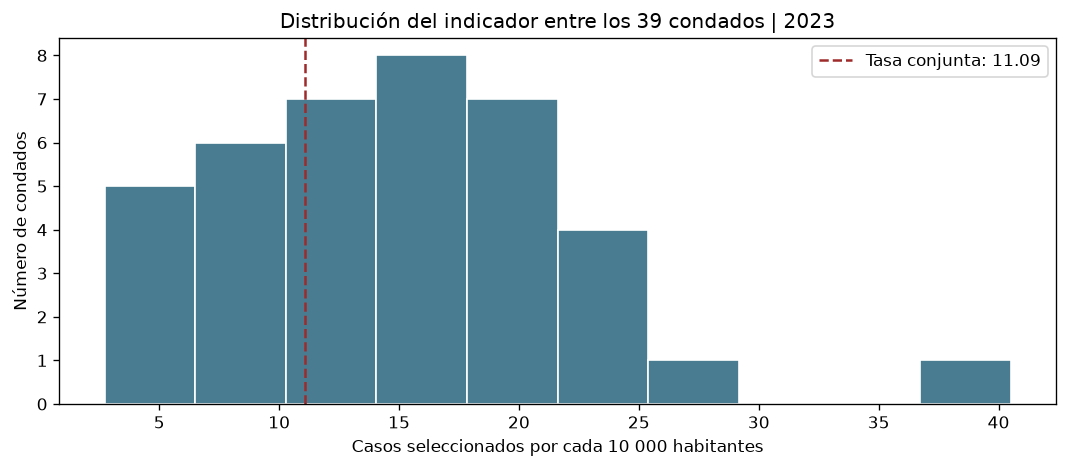

In [7]:
clasificador = mapclassify.FisherJenks(mapa.tasa_10k.to_numpy(), k=3)
ETIQUETAS = ['Menor indicador', 'Indicador intermedio', 'Mayor indicador']
COLORES = ['#e5f5e0', '#a1d99b', '#238b45']
mapa['clase_id'] = clasificador.yb
mapa['clase'] = pd.Categorical.from_codes(clasificador.yb, ETIQUETAS, ordered=True)
cortes = clasificador.bins.astype(float)
limites = [float(mapa.tasa_10k.min())] + cortes[:-1].tolist()
clases = pd.DataFrame({
    'clase': ETIQUETAS,
    'intervalo_casos_por_10k': [
        f"{'[' if i == 0 else '('}{limites[i]:.4f}, {cortes[i]:.4f}]" for i in range(3)
    ],
    'numero_condados': np.bincount(clasificador.yb, minlength=3)
})
mapa['puesto'] = mapa.tasa_10k.rank(method='min', ascending=True).astype(int)
ranking = mapa.drop(columns='geometry').sort_values(['tasa_10k', 'county_key']).reset_index(drop=True)
display(mapa[['SCF_ASSAULT', 'SCF_DRUG_CR', 'POP_TOTAL', 'tasa_10k']].describe().round(3))
display(clases)
display(ranking[['puesto', 'county_key', 'POP_TOTAL', 'SCF_ASSAULT', 'SCF_DRUG_CR', 'indicador', 'tasa_10k', 'clase']])

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(mapa.tasa_10k, bins=10, color='#4a7c91', edgecolor='white')
ax.axvline(tasa_estatal, color='#9e2a2b', linestyle='--', label=f'Tasa conjunta: {tasa_estatal:.2f}')
ax.set(xlabel='Casos seleccionados por cada 10 000 habitantes', ylabel='Número de condados',
       title='Distribución del indicador entre los 39 condados | 2023')
ax.legend()
fig.tight_layout()
fig.savefig(SALIDA / '01_distribucion_indicador.png', dpi=220, bbox_inches='tight')
plt.show()


## 8. Coherencia entre las dos capas e interpolación areal

`dissolve` une las zonas censales de un mismo condado. Su contorno se compara con el shapefile de condados mediante intersección, unión y diferencia simétrica. Dos productos de distinta fecha o generalización pueden representar de manera diferente costas y límites; una diferencia de área no demuestra por sí sola que el CRS esté equivocado. Los porcentajes siguientes describen diferencias entre productos cartográficos, no errores estadísticos del indicador.

La fuente censal corresponde a **2018 y escala 1:500 000**, mientras que el análisis estadístico corresponde a 2023. Los tracts se usan como referencia de esa edición. El código exige una coincidencia del punto con esa capa y no sustituye sus identificadores por los de una edición censal actual.

La interpolación complementaria usa el indicador como variable **intensiva**: lo pondera por la superficie de intersección respecto al área del polígono receptor. Los conteos y la población son variables extensivas, pero no se reparten como si se conociera su ubicación local. Para evitar diferencias de borde al demostrar el método, la fuente de interpolación se reconstruye con los mismos tracts. Así, cada tract recibe la tasa de su condado. Esto es una transferencia bajo un supuesto de uniformidad, no una observación local ni una predicción validada.


,county_key,fips_id,coincidencia_area_pct,diferencia_simetrica_km2
19,SAN JUAN,53055,31.038,1110.571
2,ISLAND,53029,40.848,795.564
32,CLALLAM,53009,66.260,2338.394
25,PACIFIC,53049,76.667,743.920
24,KITSAP,53035,76.735,340.966
37,JEFFERSON,53031,83.575,930.559
27,GRAYS HARBOR,53027,86.341,793.036
22,WHATCOM,53073,86.455,879.058
23,SKAGIT,53057,91.622,416.340
11,PIERCE,53053,94.017,279.844


Diferencia máxima entre tasa transferida e interpolada: 1.6802022955175744e-06


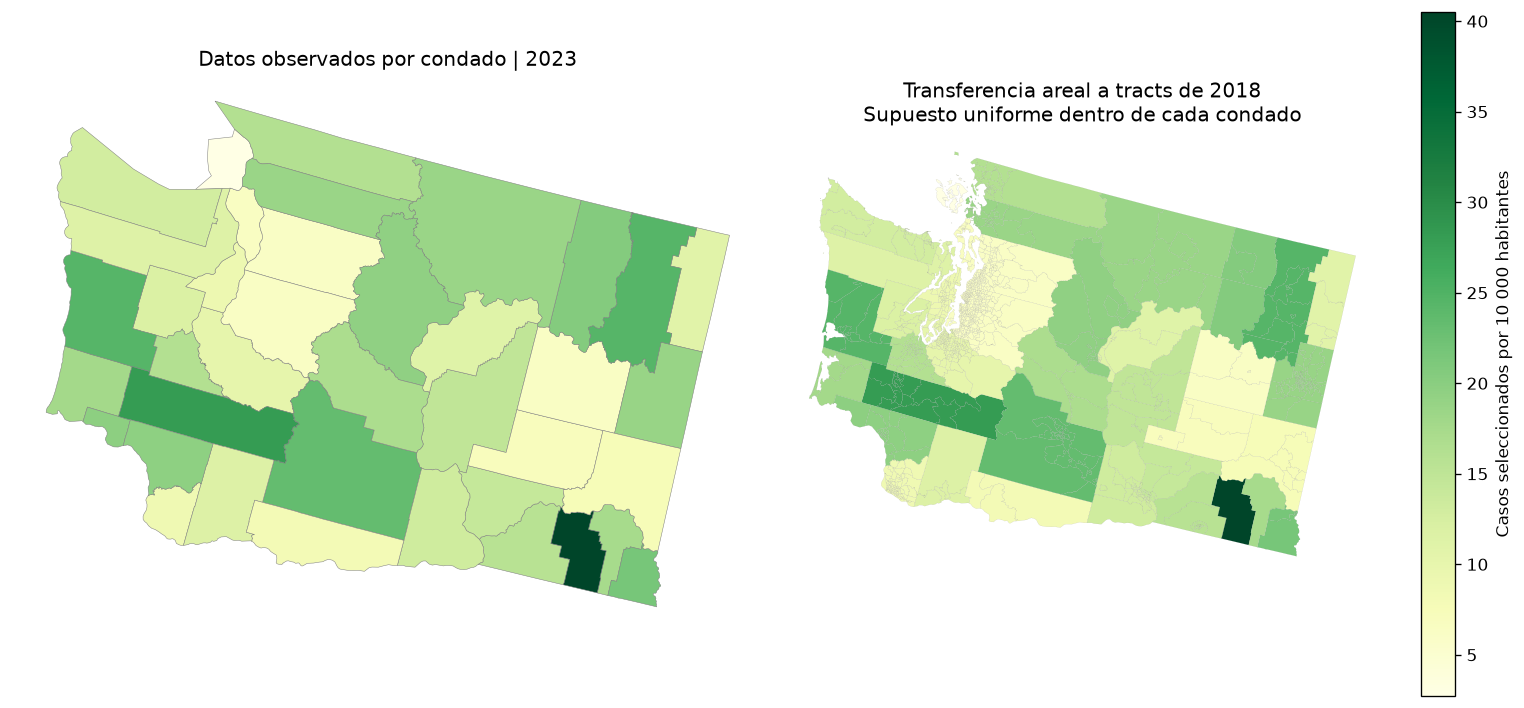

In [8]:
fuente_censal = censales[['fips_id', 'geometry']].dissolve(by='fips_id', as_index=False)
comparacion = condados.merge(
    fuente_censal.rename_geometry('geometry_censal'), on='fips_id', validate='one_to_one'
)
revision_geometrica = []
for _, fila in comparacion.iterrows():
    a, b = fila.geometry, fila.geometry_censal
    union = a.union(b).area
    revision_geometrica.append({
        'county_key': fila.county_key,
        'fips_id': fila.fips_id,
        'coincidencia_area_pct': 100 * a.intersection(b).area / union,
        'diferencia_simetrica_km2': a.symmetric_difference(b).area / 1e6
    })
revision_geometrica = pd.DataFrame(revision_geometrica)
display(revision_geometrica.sort_values('coincidencia_area_pct').head(10).round(3))

# La tabla se une por código administrativo. No se presenta como una tasa medida por tract.
tracts = censales[['tract_id', 'fips_id', 'geometry']].merge(
    mapa[['fips_id', 'county_key', 'tasa_10k', 'clase_id']],
    on='fips_id', how='left', validate='many_to_one'
).rename(columns={'tasa_10k': 'tasa_condado_10k'})
assert tracts.tasa_condado_10k.notna().all()

if EJECUTAR_INTERPOLACION:
    from tobler.area_weighted import area_interpolate
    fuente = fuente_censal.merge(mapa[['fips_id', 'tasa_10k']], on='fips_id', validate='one_to_one')
    objetivo = censales[['tract_id', 'geometry']].set_index('tract_id')
    interpolado = area_interpolate(
        source_df=fuente, target_df=objetivo, intensive_variables=['tasa_10k']
    )
    # Se alinea por identificador, nunca por una posición de fila supuesta.
    valores = interpolado['tasa_10k'].rename('tasa_areal_10k')
    if not valores.index.equals(objetivo.index):
        raise ValueError('La salida de Tobler cambió el índice. Revisar la alineación antes de concatenar.')
    tracts = tracts.merge(valores, left_on='tract_id', right_index=True, validate='one_to_one')
    error_max = float((tracts.tasa_areal_10k - tracts.tasa_condado_10k).abs().max())
    print('Diferencia máxima entre tasa transferida e interpolada:', error_max)
    assert np.allclose(tracts.tasa_areal_10k, tracts.tasa_condado_10k, rtol=1e-4, atol=1e-4)
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    minimo, maximo = float(mapa.tasa_10k.min()), float(mapa.tasa_10k.max())
    mapa.plot(column='tasa_10k', ax=axes[0], cmap='YlGn', vmin=minimo, vmax=maximo, linewidth=.3, edgecolor='grey')
    tracts.plot(column='tasa_areal_10k', ax=axes[1], cmap='YlGn', vmin=minimo, vmax=maximo,
                linewidth=.05, edgecolor='grey', legend=True,
                legend_kwds={'label': 'Casos seleccionados por 10 000 habitantes'})
    axes[0].set_title('Datos observados por condado | 2023')
    axes[1].set_title('Transferencia areal a tracts de 2018\nSupuesto uniforme dentro de cada condado')
    for ax in axes:
        ax.set_axis_off()
    fig.tight_layout()
    fig.savefig(SALIDA / '02_comparacion_areal.png', dpi=220, bbox_inches='tight')
    plt.show()
else:
    print('Interpolación desactivada. Se conserva el análisis principal por condado.')


## 9. Ubicación de la propiedad

Se consulta la dirección en el **Census Geocoder** y se muestra la dirección coincidente, sus coordenadas y el método utilizado. Si no se obtiene una coincidencia en Washington, se intenta Nominatim, como en los ejemplos de clase. Si ambos servicios fallan, se solicita revisar la dirección o introducir coordenadas verificadas; no se inventa una ubicación. Las respuestas exitosas se guardan para evitar consultas repetidas.

La geocodificación devuelve una posición asociada a la dirección; el Census Geocoder puede interpolarla a lo largo de un tramo de calle. No equivale a un levantamiento del lote. Las coordenadas se reproyectan al CRS del análisis y `sjoin` identifica el condado y el tract de 2018 que intersectan el punto. Debe existir una correspondencia única y coherente entre las capas antes de formular la recomendación.


In [9]:
clave_direccion = hashlib.sha256(DIRECCION.encode('utf-8')).hexdigest()[:16]
cache = SALIDA / f'geocodificacion_{clave_direccion}.json'
if COORDENADAS_MANUALES is not None:
    if not FUENTE_COORDENADAS.strip():
        raise ValueError('Indica la fuente de las coordenadas manuales verificadas.')
    lon, lat = map(float, COORDENADAS_MANUALES)
    ubicacion = {'consulta': DIRECCION, 'direccion_obtenida': DIRECCION,
                 'longitud': lon, 'latitud': lat, 'metodo': 'Coordenadas manuales verificadas',
                 'fuente': FUENTE_COORDENADAS}
elif cache.exists():
    ubicacion = json.loads(cache.read_text(encoding='utf-8'))
    if ubicacion['consulta'] != DIRECCION:
        raise ValueError('El caché corresponde a otra dirección.')
else:
    errores = []
    ubicacion = None
    parametros = {'address': DIRECCION.replace(', USA', ''),
                  'benchmark': 'Public_AR_Current', 'format': 'json'}
    url_census = 'https://geocoding.geo.census.gov/geocoder/locations/onelineaddress?' + urlencode(parametros)
    try:
        respuesta = json.loads(obtener_bytes(url_census, intentos=2))
        coincidencias = respuesta['result']['addressMatches']
        coincidencias = [c for c in coincidencias if c['addressComponents'].get('state') == 'WA']
        if len(coincidencias) == 1:
            coincidencia = coincidencias[0]
            ubicacion = {'consulta': DIRECCION, 'direccion_obtenida': coincidencia['matchedAddress'],
                         'longitud': float(coincidencia['coordinates']['x']),
                         'latitud': float(coincidencia['coordinates']['y']),
                         'metodo': 'U.S. Census Geocoder / Public_AR_Current',
                         'fuente': url_census, 'respuesta': coincidencia}
        else:
            errores.append(f'Census Geocoder: {len(coincidencias)} coincidencias en Washington.')
    except Exception as exc:
        errores.append('Census Geocoder: ' + str(exc))
    if ubicacion is None:
        try:
            geolocator = Nominatim(user_agent='pucp_datos_espaciales_t2_washington_v2', timeout=20)
            lugar = geolocator.geocode(DIRECCION, country_codes='us', addressdetails=True, exactly_one=True)
            if lugar:
                ubicacion = {'consulta': DIRECCION, 'direccion_obtenida': lugar.address,
                             'longitud': float(lugar.longitude), 'latitud': float(lugar.latitude),
                             'metodo': 'Nominatim / OpenStreetMap', 'respuesta': lugar.raw}
        except Exception as exc:
            errores.append('Nominatim: ' + str(exc))
    if ubicacion is None:
        raise RuntimeError('No se obtuvo una ubicación. Revisa la dirección o introduce coordenadas verificadas. '
                           + ' | '.join(errores))
    ubicacion['fecha_consulta_utc'] = datetime.now(timezone.utc).isoformat()
    cache.write_text(json.dumps(ubicacion, ensure_ascii=False, indent=2), encoding='utf-8')

lon, lat = ubicacion['longitud'], ubicacion['latitud']
if not np.isfinite([lon, lat]).all() or not (-180 <= lon <= 180 and -90 <= lat <= 90):
    raise ValueError('Coordenadas inválidas. Usar (longitud, latitud) en grados.')
display(pd.DataFrame([{k: v for k, v in ubicacion.items() if k != 'respuesta'}]).T.rename(columns={0:'Resultado'}))
punto = gpd.GeoDataFrame({'direccion': [DIRECCION]}, geometry=[Point(lon, lat)], crs='EPSG:4326').to_crs(CRS_ANALISIS)
consulta_condado = punto.sjoin(mapa, how='left', predicate='intersects')
consulta_tract = punto.sjoin(censales[['tract_id', 'fips_id', 'geometry']], how='left', predicate='intersects')
if len(consulta_condado) != 1 or consulta_condado.fips_id.isna().any():
    raise ValueError('El punto no tiene un condado único en Washington. Revisar la dirección y sus coordenadas.')
if len(consulta_tract) != 1 or consulta_tract.tract_id.isna().any():
    raise ValueError('El punto no tiene un tract único en la capa de 2018. Revisar límites y geocodificación.')
resultado_propiedad = consulta_condado.iloc[0]
if consulta_tract.iloc[0].fips_id != resultado_propiedad.fips_id:
    raise ValueError('Las dos capas asignan condados diferentes al punto. Revisar antes de interpretar.')
if CONDADO_ESPERADO and resultado_propiedad.county_key != CONDADO_ESPERADO.strip().upper():
    raise ValueError('El condado obtenido difiere del esperado. Verifica que el geocodificador encontró la propiedad correcta.')
tract_propiedad = consulta_tract.iloc[0].tract_id
display(pd.DataFrame([{
    'direccion': DIRECCION, 'condado': resultado_propiedad.county_key,
    'FIPS': resultado_propiedad.fips_id, 'tract_2018': tract_propiedad,
    'tasa_por_10k': resultado_propiedad.tasa_10k,
    'clase_relativa': str(resultado_propiedad.clase), 'puesto_menor_a_mayor': resultado_propiedad.puesto
}]))


,Resultado
consulta,"1321 Seneca St, Seattle, WA 98101, USA"
direccion_obtenida,"1321 SENECA ST, SEATTLE, WA, 98101"
longitud,-122.323911
latitud,47.611757
metodo,U.S. Census Geocoder / Public_AR_Current
fuente,https://geocoding.geo.census.gov/geocoder/loca...
fecha_consulta_utc,2026-11-02T22:56:12.542510+00:00


,direccion,condado,FIPS,tract_2018,tasa_por_10k,clase_relativa,puesto_menor_a_mayor
0,"1321 Seneca St, Seattle, WA 98101, USA",KING,53033,53033008400,6.401738,Menor indicador,4


## 10. Mapas finales y comparación de la propiedad

El primer panel sitúa la propiedad dentro de Washington y clasifica los condados. El segundo muestra el contexto inmediato, las zonas censales y el tract de la propiedad. Sus colores representan siempre el valor del condado. La escala local se elige para mostrar un entorno de aproximadamente 12 km de ancho; no define un radio de evaluación de la seguridad.

El gráfico de barras ordena los condados de menor a mayor indicador. La línea vertical corresponde a la tasa conjunta de los 39 condados. El color de la barra destaca el condado de la propiedad.


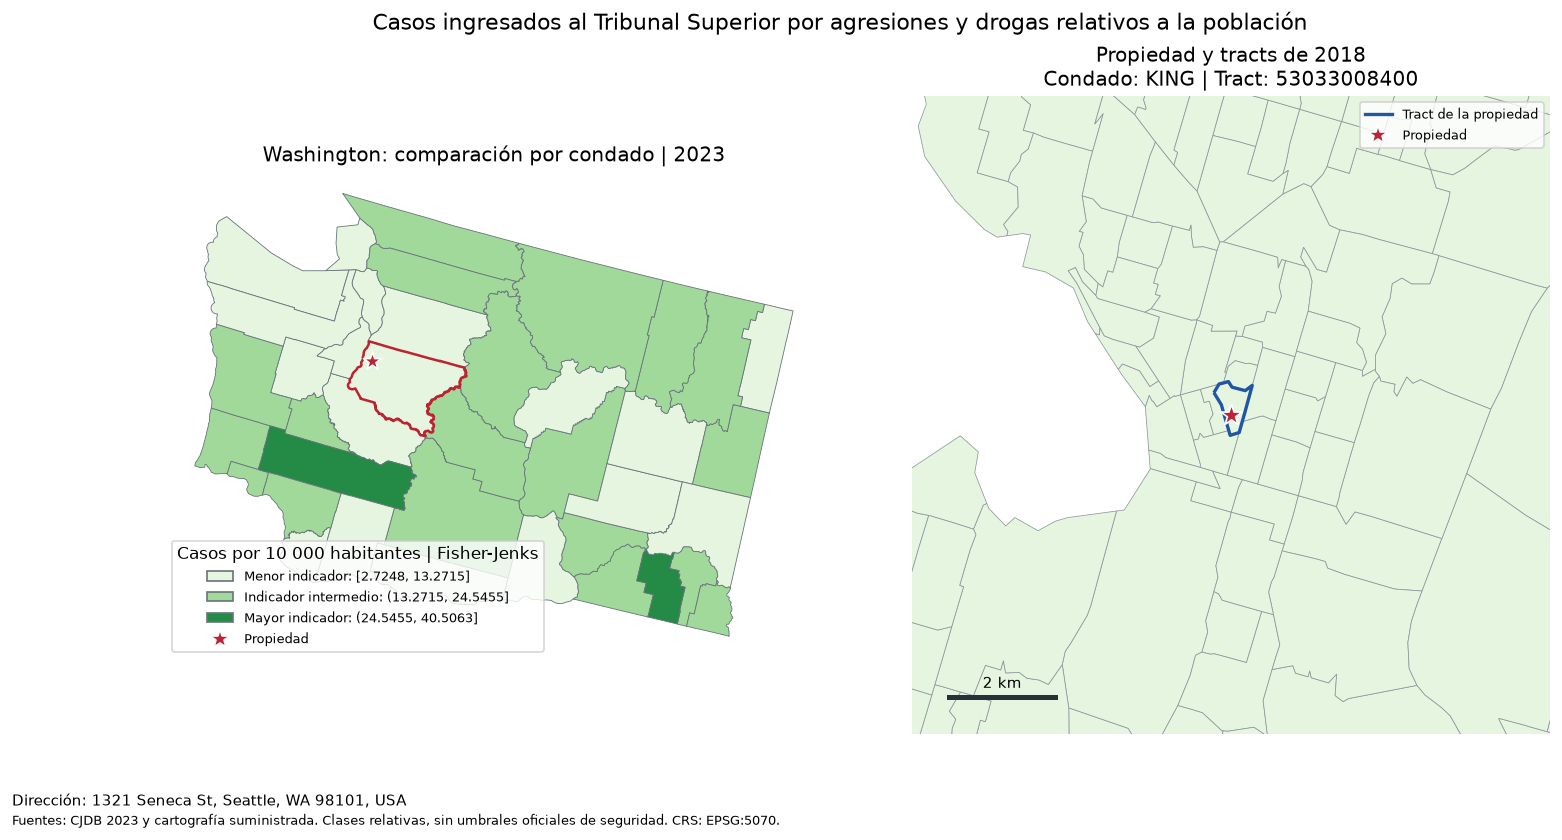

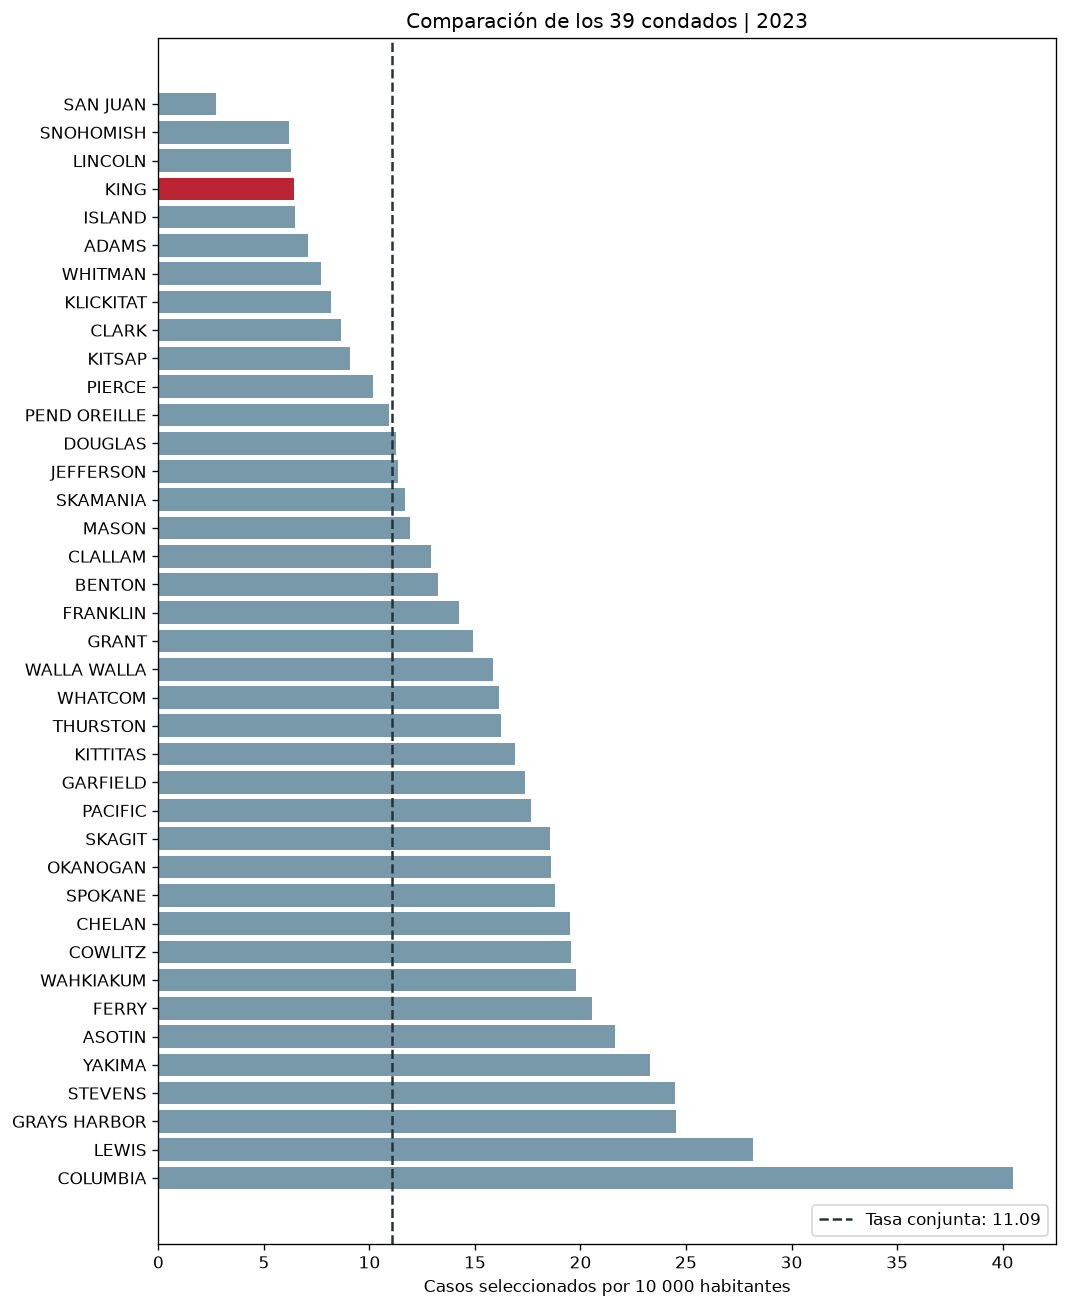

In [10]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
colores_mapa = mapa.clase_id.map(dict(enumerate(COLORES)))
mapa.plot(ax=axes[0], color=colores_mapa, edgecolor='#68737a', linewidth=.5)
punto.plot(ax=axes[0], color='#bc2333', marker='*', markersize=130, edgecolor='white', zorder=5)
mapa.loc[mapa.fips_id.eq(resultado_propiedad.fips_id)].boundary.plot(ax=axes[0], color='#bc2333', linewidth=1.5)
axes[0].set_title('Washington: comparación por condado | 2023')
leyenda = [Patch(facecolor=COLORES[i], edgecolor='#68737a',
                 label=f'{ETIQUETAS[i]}: {clases.iloc[i].intervalo_casos_por_10k}') for i in range(3)]
leyenda.append(Line2D([0], [0], marker='*', color='white', markerfacecolor='#bc2333', markersize=12, label='Propiedad'))
axes[0].legend(handles=leyenda, loc='lower left', fontsize=8, frameon=True,
               title='Casos por 10 000 habitantes | Fisher-Jenks')

x, y = punto.geometry.iloc[0].x, punto.geometry.iloc[0].y
ventana = (x - 6000, y - 6000, x + 6000, y + 6000)
local = tracts.cx[ventana[0]:ventana[2], ventana[1]:ventana[3]]
local.plot(ax=axes[1], color=local.clase_id.map(dict(enumerate(COLORES))), edgecolor='#8e969b', linewidth=.45)
mapa.boundary.plot(ax=axes[1], color='#263238', linewidth=1.2)
censales.loc[censales.tract_id.eq(tract_propiedad)].boundary.plot(ax=axes[1], color='#2056a3', linewidth=2)
punto.plot(ax=axes[1], marker='*', color='#bc2333', markersize=180, edgecolor='white', zorder=5)
axes[1].set_xlim(ventana[0], ventana[2]); axes[1].set_ylim(ventana[1], ventana[3])
axes[1].set_title(f'Propiedad y tracts de 2018\nCondado: {resultado_propiedad.county_key} | Tract: {tract_propiedad}')
axes[1].legend(handles=[Line2D([0],[0], color='#2056a3', lw=2, label='Tract de la propiedad'),
                        leyenda[-1]], loc='upper right', fontsize=8)
# Escala gráfica del panel local: coordenadas métricas en EPSG:5070.
xb, yb, longitud_barra = ventana[0] + 700, ventana[1] + 700, 2000
axes[1].plot([xb, xb + longitud_barra], [yb, yb], color='#263238', lw=3)
axes[1].text(xb + longitud_barra / 2, yb + 170, '2 km', ha='center', fontsize=9)
for ax in axes:
    ax.set_axis_off()
fig.suptitle('Casos ingresados al Tribunal Superior por agresiones y drogas relativos a la población', fontsize=13)
fig.text(.04, .035, f'Dirección: {DIRECCION}', fontsize=9)
fig.text(.04, .012, 'Fuentes: CJDB 2023 y cartografía suministrada. Clases relativas, sin umbrales oficiales de seguridad. CRS: EPSG:5070.', fontsize=8)
fig.subplots_adjust(bottom=.12, top=.88, wspace=.12)
imagen_final = BytesIO()
fig.savefig(imagen_final, format='png', dpi=250, bbox_inches='tight')
(SALIDA / '03_mapa_final_propiedad.png').write_bytes(imagen_final.getvalue())
plt.show()

fig, ax = plt.subplots(figsize=(9, 11))
barras = ranking.county_key.eq(resultado_propiedad.county_key).map({True:'#bc2333', False:'#7799a9'})
ax.barh(ranking.county_key, ranking.tasa_10k, color=barras)
ax.axvline(tasa_estatal, color='#263238', linestyle='--', label=f'Tasa conjunta: {tasa_estatal:.2f}')
ax.invert_yaxis()
ax.set(xlabel='Casos seleccionados por 10 000 habitantes', title='Comparación de los 39 condados | 2023')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(SALIDA / '04_comparacion_condados.png', dpi=220, bbox_inches='tight')
plt.show()


### 10.1. Mapa interactivo

`explore` genera un mapa navegable con Folium y Leaflet. Se puede acercar, consultar cada condado y activar las zonas censales cercanas. No cambia el cálculo: presenta los mismos resultados del mapa estático. El fondo cartográfico necesita conexión. El HTML interactivo se considera parte de la presentación y se mantiene fuera de GitHub junto con el dashboard.


In [11]:
if CREAR_MAPA_INTERACTIVO:
    import folium
    mapa_web = mapa.copy()
    mapa_web['clase'] = mapa_web.clase.astype(str)
    mapa_web = mapa_web.to_crs(4326)
    visor = mapa_web.explore(
        column='tasa_10k', cmap='YlGn', tiles='OpenStreetMap', name='Indicador por condado | 2023',
        tooltip=['county_key', 'POP_TOTAL', 'SCF_ASSAULT', 'SCF_DRUG_CR', 'tasa_10k', 'clase', 'puesto'],
        tooltip_kwds={'aliases':['Condado', 'Población', 'Casos por agresiones', 'Casos por drogas',
                                'Casos por 10 000', 'Clase relativa', 'Puesto (menor a mayor)']},
        legend_kwds={'caption': 'Casos seleccionados por 10 000 habitantes | 2023'},
        style_kwds={'weight':.7, 'fillOpacity':.65}
    )
    local[['tract_id', 'geometry']].to_crs(4326).explore(
        m=visor, name='Tracts de 2018 próximos a la propiedad', tooltip=['tract_id'],
        color='#536170', style_kwds={'fillOpacity':0, 'weight':.6}, show=False
    )
    folium.Marker([lat, lon], tooltip=DIRECCION,
                  popup=folium.Popup(html.escape(f'{DIRECCION} | {resultado_propiedad.county_key} | '
                           f'{resultado_propiedad.tasa_10k:.2f} casos por 10 000'), max_width=350),
                  icon=folium.Icon(color='red', icon='home')).add_to(visor)
    folium.LayerControl(collapsed=False).add_to(visor)
    PRESENTACION = BASE / 'Presentacion_V2'
    PRESENTACION.mkdir(exist_ok=True)
    visor.save(str(PRESENTACION / 'mapa_interactivo.html'))
    display(visor)


## 11. Interpretación y recomendación

La siguiente celda redacta el resultado a partir de la dirección y los cálculos efectivamente obtenidos. Un puesto bajo representa un indicador menor. Los empates comparten puesto. La recomendación se restringe al criterio de la actividad: no se atribuye al vecindario una tasa observada que solo se conoce por condado.


In [12]:
valor = float(resultado_propiedad.tasa_10k)
menores = int((mapa.tasa_10k < valor).sum())
iguales = int(np.isclose(mapa.tasa_10k, valor, rtol=0, atol=1e-10).sum())
mayores = len(mapa) - menores - iguales
comparativo = 'inferior a' if valor < tasa_estatal else ('superior a' if valor > tasa_estatal else 'igual a')
diferencia_pct = (valor / tasa_estatal - 1) * 100 if tasa_estatal else np.nan
if int(resultado_propiedad.clase_id) == 0:
    sugerencia = ('Bajo el único criterio solicitado, el condado presenta un contexto comparativamente favorable '
                  'dentro del conjunto analizado. La propiedad puede mantenerse entre las alternativas a evaluar, '
                  'sin interpretar esta clasificación como garantía de seguridad del vecindario.')
elif int(resultado_propiedad.clase_id) == 1:
    sugerencia = ('Bajo el único criterio solicitado, el condado ocupa una clase intermedia. '
                  'El resultado no ofrece una ventaja clara frente a los condados de menor indicador. '
                  'Conviene comparar alternativas en estos últimos antes de formular una preferencia por ubicación.')
else:
    sugerencia = ('Bajo el único criterio solicitado, el condado pertenece al grupo de mayor indicador. '
                  'Si se prioriza reducir este valor, conviene considerar alternativas en condados con valores menores. '
                  'Esto no implica que todos los sectores del condado tengan el mismo contexto local de seguridad.')

informe = f"""### Resultado para la propiedad

La dirección **{DIRECCION}** fue localizada en el condado **{resultado_propiedad.county_key}**,
con código FIPS **{resultado_propiedad.fips_id}**, y en el tract **{tract_propiedad}** de la capa censal de 2018.

En 2023, el condado registró **{int(resultado_propiedad.SCF_ASSAULT):,}** casos en la categoría de agresiones y
**{int(resultado_propiedad.SCF_DRUG_CR):,}** en la categoría de drogas, para una población de
**{int(resultado_propiedad.POP_TOTAL):,} habitantes**. La suma equivale a **{valor:.2f} casos por cada 10 000 habitantes**
({float(resultado_propiedad.indicador):.6f} casos por habitante).

El indicador es **{comparativo}** la tasa conjunta de los 39 condados (**{tasa_estatal:.2f}** por 10 000),
con una diferencia relativa de **{diferencia_pct:+.1f}%**. Ocupa el puesto **{int(resultado_propiedad.puesto)} de 39**,
ordenando de menor a mayor: {menores} condados presentan un valor menor, {mayores} uno mayor
y {iguales} tienen el mismo valor, incluido este condado. Su clase Fisher-Jenks es **{resultado_propiedad.clase}**.

### Sugerencia

{sugerencia}

La información permite evaluar el contexto judicial relativo del condado en 2023. No permite medir la
probabilidad individual de ser víctima, afirmar que una calle sea segura ni describir las condiciones actuales.
La transferencia a tracts reproduce un supuesto espacial y no modifica esta limitación.
"""
display(Markdown(informe))


### Resultado para la propiedad

La dirección **1321 Seneca St, Seattle, WA 98101, USA** fue localizada en el condado **KING**,
con código FIPS **53033**, y en el tract **53033008400** de la capa censal de 2018.

En 2023, el condado registró **1,221** casos en la categoría de agresiones y
**282** en la categoría de drogas, para una población de
**2,347,800 habitantes**. La suma equivale a **6.40 casos por cada 10 000 habitantes**
(0.000640 casos por habitante).

El indicador es **inferior a** la tasa conjunta de los 39 condados (**11.09** por 10 000),
con una diferencia relativa de **-42.3%**. Ocupa el puesto **4 de 39**,
ordenando de menor a mayor: 3 condados presentan un valor menor, 35 uno mayor
y 1 tienen el mismo valor, incluido este condado. Su clase Fisher-Jenks es **Menor indicador**.

### Sugerencia

Bajo el único criterio solicitado, el condado presenta un contexto comparativamente favorable dentro del conjunto analizado. La propiedad puede mantenerse entre las alternativas a evaluar, sin interpretar esta clasificación como garantía de seguridad del vecindario.

La información permite evaluar el contexto judicial relativo del condado en 2023. No permite medir la
probabilidad individual de ser víctima, afirmar que una calle sea segura ni describir las condiciones actuales.
La transferencia a tracts reproduce un supuesto espacial y no modifica esta limitación.


## 12. Exportación y trazabilidad

Los resultados se guardan en `Resultados_V2`: tablas CSV, capas GeoJSON, figuras y un resumen en Markdown. Los archivos fuente permanecen intactos. Se genera también un manifiesto con la huella SHA-256 de los insumos para identificar qué archivos se utilizaron y las versiones de las bibliotecas del kernel.

La presentación HTML y la plantilla opcional de Flexdashboard se guardan en `Presentacion_V2`, que debe excluirse del repositorio. El cuaderno no crea repositorios ni publica contenido automáticamente. No subas esa carpeta a GitHub.


In [13]:
ranking.to_csv(SALIDA / 'resultados_condados_2023.csv', index=False, encoding='utf-8-sig')
excluidos.to_csv(SALIDA / 'registros_excluidos_2023.csv', index=False, encoding='utf-8-sig')
clases.to_csv(SALIDA / 'limites_clasificacion.csv', index=False, encoding='utf-8-sig')
revision_geometrica.to_csv(SALIDA / 'revision_geometrica.csv', index=False, encoding='utf-8-sig')
mapa_exportar = mapa.copy()
mapa_exportar['clase'] = mapa_exportar.clase.astype(str)
mapa_exportar.to_crs(4326).to_file(SALIDA / 'condados_indicador_2023.geojson', driver='GeoJSON')
tracts.to_crs(4326).to_file(SALIDA / 'tracts_referencia_tasa_condado.geojson', driver='GeoJSON')
consulta_exportar = consulta_condado.drop(columns='index_right', errors='ignore').copy()
consulta_exportar['clase'] = consulta_exportar.clase.astype(str)
consulta_exportar['tract_2018'] = tract_propiedad
consulta_exportar.to_crs(4326).to_file(SALIDA / 'propiedad_analizada.geojson', driver='GeoJSON')
(SALIDA / 'interpretacion_resultados.md').write_text(informe, encoding='utf-8')

def sha256_archivo(ruta):
    h = hashlib.sha256()
    with ruta.open('rb') as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()

versiones = {}
for paquete in ['pandas', 'openpyxl', 'geopandas', 'matplotlib', 'mapclassify', 'geopy', 'folium', 'tobler']:
    try:
        versiones[paquete] = metadata.version(paquete)
    except metadata.PackageNotFoundError:
        versiones[paquete] = 'No instalado'
manifiesto = {
    'repositorio': REPOSITORIO, 'commit_github': COMMIT_GITHUB,
    'inventario_remoto': inventario.to_dict(orient='records'),
    'anio_estadistico': ANIO, 'edicion_cartografia_censal': 2018,
    'formula': '(SCF_ASSAULT + SCF_DRUG_CR) / POP_TOTAL', 'escala_presentacion': ESCALA,
    'direccion': DIRECCION, 'fuente_direccion': FUENTE_DIRECCION,
    'condado': resultado_propiedad.county_key, 'tract_2018': tract_propiedad,
    'crs_analisis': CRS_ANALISIS, 'clasificacion': 'FisherJenks k=3', 'cortes_10k': cortes.tolist(),
    'versiones': versiones,
    'insumos': [{'archivo': p.relative_to(DATA).as_posix(), 'sha256': sha256_archivo(p)}
                for p in sorted(DATA.rglob('*')) if p.is_file()]
}
(SALIDA / 'trazabilidad.json').write_text(json.dumps(manifiesto, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame({'archivo_generado': [p.name for p in sorted(SALIDA.iterdir()) if p.is_file()]}))

for nombre in ['01_distribucion_indicador.png', '02_comparacion_areal.png',
               '03_mapa_final_propiedad.png', '04_comparacion_condados.png']:
    if nombre == '02_comparacion_areal.png' and not EJECUTAR_INTERPOLACION:
        continue
    imagen = SALIDA / nombre
    if not imagen.exists() or not imagen.read_bytes().startswith(b'\x89PNG\r\n\x1a\n'):
        raise RuntimeError(f'La figura {nombre} no se exportó correctamente. Ejecuta de nuevo su celda.')
print('Figuras PNG exportadas y comprobadas.')


,archivo_generado
0,01_distribucion_indicador.png
1,02_comparacion_areal.png
2,03_mapa_final_propiedad.png
3,04_comparacion_condados.png
4,condados_indicador_2023.geojson
5,geocodificacion_e0a6e1062e3e804f.json
6,interpretacion_resultados.md
7,limites_clasificacion.csv
8,propiedad_analizada.geojson
9,registros_excluidos_2023.csv


Figuras PNG exportadas y comprobadas.


### 12.1. Presentación opcional en R y Flexdashboard

Esta celda prepara una plantilla `.Rmd` que reúne el mapa final de Python, una tabla comparativa y la interpretación calculada. Copia sus insumos en la carpeta de presentación para que pueda trasladarse completa. El HTML final se renderiza en R, no en el kernel Python. Requiere R, RStudio o Pandoc y los paquetes `rmarkdown`, `flexdashboard`, `knitr` y `DT`.

En la consola de R, abre la carpeta de presentación y ejecuta:

```r
install.packages(c("rmarkdown", "flexdashboard", "knitr", "DT"))
rmarkdown::render("dashboard_washington.Rmd", encoding = "UTF-8")
```

Este paso es complementario a la entrega del cuaderno. El dashboard se entrega por separado y no se sube a GitHub.


In [14]:
if GENERAR_PLANTILLA_R:
    import shutil
    PRESENTACION = BASE / 'Presentacion_V2'
    PRESENTACION.mkdir(exist_ok=True)
    for nombre in ['resultados_condados_2023.csv', '03_mapa_final_propiedad.png',
                   '04_comparacion_condados.png', 'interpretacion_resultados.md']:
        shutil.copy2(SALIDA / nombre, PRESENTACION / nombre)
    plantilla_r = r"""---
title: "Washington: contexto de una propiedad | 2023"
output:
  flexdashboard::flex_dashboard:
    orientation: rows
    vertical_layout: scroll
    self_contained: true
---

```{r setup, include=FALSE}
library(flexdashboard)
library(knitr)
library(DT)
knitr::opts_chunk$set(echo=FALSE, warning=FALSE, message=FALSE)
tabla <- read.csv("resultados_condados_2023.csv", fileEncoding="UTF-8-BOM")
```

Mapa y propiedad
=======================================================================

Row
-----------------------------------------------------------------------

### Mapa final producido en Python
```{r, out.width='100%'}
knitr::include_graphics("03_mapa_final_propiedad.png")
```

Resultados
=======================================================================

Row
-----------------------------------------------------------------------

### Comparación de condados
```{r}
DT::datatable(tabla[, c("puesto", "county_key", "POP_TOTAL", "SCF_ASSAULT",
                        "SCF_DRUG_CR", "tasa_10k", "clase")],
              rownames=FALSE, options=list(pageLength=10, scrollX=TRUE))
```

Interpretación
=======================================================================

### Resultado y sugerencia
```{r, results='asis'}
cat(readLines("interpretacion_resultados.md", encoding="UTF-8"), sep="\n")
```

Método y fuentes
=======================================================================

### Alcance

Integrantes: 1. __________________; 2. __________________; 3. __________________.

El indicador es (SCF_ASSAULT + SCF_DRUG_CR) / POP_TOTAL, para 2023.
Se presenta por 10 000 habitantes. Los datos son casos ingresados al Tribunal Superior,
no el total de delitos ni una probabilidad de victimización. La unidad estadística es el condado.
Los tracts corresponden a cartografía de 2018. Las clases Fisher-Jenks son relativas y no son
umbrales oficiales de seguridad. La geocodificación sitúa el edificio y no verifica su venta.

Fuentes: Washington State Criminal Justice Data Book and Data Definitions (2024),
Excel CJDB90_23 y capas suministradas en la actividad. Fuente de la dirección inicial:
https://www.seattle.gov/dpd/AppDocs/GroupMeetings/DRProposal3012930AgendaID4238.pdf
"""
    (PRESENTACION / 'dashboard_washington.Rmd').write_text(plantilla_r, encoding='utf-8')
    print('Presentación preparada en:', PRESENTACION)
    print('Para obtener el dashboard HTML, renderiza el .Rmd en R.')


Presentación preparada en: d:\pucp\9no ciclo\Datos espaciales\Códigos Python\Tareas grupales\T2\Presentacion_V2
Para obtener el dashboard HTML, renderiza el .Rmd en R.


## 13. Organización de la entrega y GitHub

Este cuaderno lee los datos desde GitHub y puede subirse al repositorio junto con las figuras estáticas y tablas de `Resultados_V2`. El dashboard y el mapa HTML se entregan por separado. No se realiza ninguna publicación automática.

Antes de entregar, completa los tres integrantes, verifica la dirección elegida y su fuente, ejecuta todo desde el inicio y guarda el cuaderno con los resultados. Si cambias la dirección o los datos, vuelve a ejecutar las celdas posteriores. En Colab descarga tanto el cuaderno ejecutado como los resultados antes de cerrar el entorno.

Agrega estas reglas al `.gitignore` del repositorio, conservando las existentes:

```gitignore
.venv/
__pycache__/
.ipynb_checkpoints/
.cache_t2/
Presentacion_V2/
Resultados_V2/geocodificacion_*.json
*.html
*.Rmd
```

VS Code puede abrir este archivo desde cualquier carpeta con permisos de escritura; Colab puede abrirlo mediante carga o desde GitHub. Ambos ejecutan la misma secuencia y descargan los insumos. No se necesitan rutas de Windows, Google Drive ni una clonación manual.


## 14. Limitaciones y fuentes

El indicador representa dos categorías de ingreso judicial por condado para 2023. Los procedimientos de denuncia, investigación y judicialización influyen en lo que llega a registrarse; no puede equipararse el resultado a todos los hechos ocurridos. Un menor valor tampoco implica ausencia de problemas de seguridad.

Los polígonos censales permiten contextualizar la ubicación, pero no contienen observaciones del indicador a esa escala. La interpolación intensiva supone uniformidad dentro del condado. No se ha utilizado información para validar diferencias entre calles o vecindarios. Las capas de distintas ediciones y escalas pueden diferir en sus límites.

La geocodificación se consulta al ejecutar el análisis y no reconstruye la posición histórica de la dirección en 2023. El informe no verifica el estado comercial, físico o legal de una propiedad. La recomendación expresa una comparación académica bajo el único indicador exigido.

**Fuentes y referencias de trabajo**

1. Washington State Statistical Analysis Center. *Washington State Criminal Justice Data Book and Data Definitions*. Actualización del 10 de octubre de 2024. Diccionario proporcionado en la actividad; definiciones de población y Superior Court Filing.
2. `cjdb90_23.xlsx`, hoja `CJDB90_23`. Base suministrada. El cuaderno utiliza únicamente las filas de 2023.
3. `WA_County_Boundaries` y `cb_2018_53_tract_500k`. Capas proporcionadas. La edición censal se identifica por el nombre de archivo; no se asume que la fecha de modificación de un archivo sea su fecha de levantamiento.
4. Ciudad de Seattle. *1321 Seneca. Design Review Proposal*, 20 de febrero de 2013. Fuente pública de la dirección residencial de ejemplo: https://www.seattle.gov/dpd/AppDocs/GroupMeetings/DRProposal3012930AgendaID4238.pdf. Consulta: 2 de noviembre de 2026. Se usa para documentar la dirección, sin adoptar las cantidades propuestas como características actuales.
5. U.S. Census Bureau. Census Geocoder: https://geocoding.geo.census.gov/geocoder/. Alternativa: Nominatim / OpenStreetMap. Geocodificación al ejecutar el cuaderno: https://nominatim.org/.
6. Repositorio de datos: https://github.com/Jose-Bautista-gnss/Evaluacion_Grupal_2. El commit se registra al ejecutar.
7. Cuadernos de clase `crime`, `airbnb` y `gasandschools`: referencia para preparación espacial, interpolación, mapas y consultas por ubicación. El avance del grupo se utilizó como referencia complementaria.
